[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D4_logloss_bernoulli.ipynb)

# D4 · Log-loss = MLE de Bernoulli = entropía cruzada

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód II).** Entropía cruzada $H(q,p)=-\sum_k q_k\log p_k$; si $q$ es degenerada, $H(q,p)=D_{KL}(q\|p)$.

**Supuestos.** $y\in\{0,1\}$ condicionalmente independientes; $P(y=1\mid x)=\sigma(\vec w\cdot x+b)$; *clipping* $\hat p\in[10^{-12},1-10^{-12}]$.

**La idea.** El gradiente del log-loss es $\frac1m\sum_i(\hat p^{(i)}-y^{(i)})x_j^{(i)}$: la misma forma que en regresión lineal. Lo verificamos con diferencias finitas y vemos por qué el MSE con sigmoide es mala idea.

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
P_HAT = 0.05   # probabilidad que el modelo le da a la clase 1 cuando la etiqueta real es y = 1

## La identidad, con números

Bernoulli −ℓ/m = 1.795086 | entropía cruzada = 1.795086 | sklearn = 1.795086 | dammg = 1.795086
∂J/∂w analítico : [-0.317   0.4495 -0.2889]
∂J/∂w numérico  : [-0.317   0.4495 -0.2889]


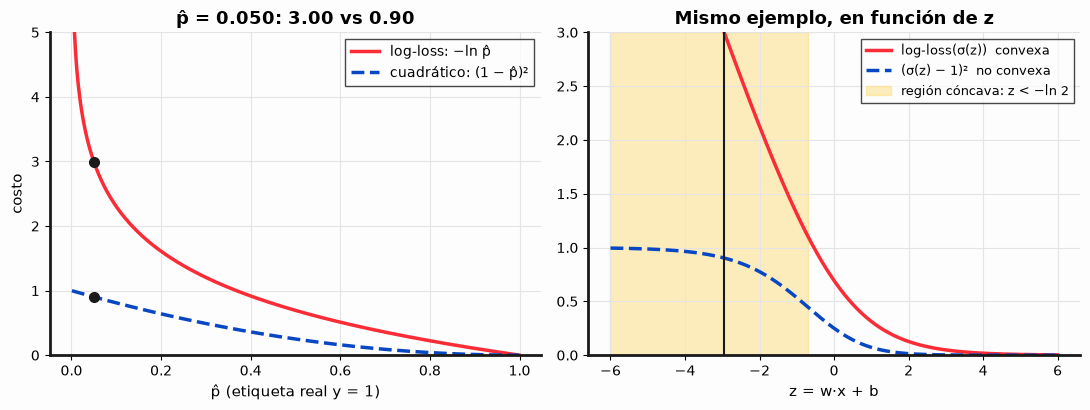

gradiente respecto a z: log-loss = p̂ − 1 = -0.950 | MSE∘σ = −2σ(1−σ)² = -0.0902


In [3]:
from sklearn.metrics import log_loss as skl_log_loss
from dammg_utils import sigmoide, log_loss

# 1) Tres caminos al mismo número
rng = np.random.default_rng(4)
m, n = 200, 3
X = rng.normal(size=(m, n)); w_r = np.array([1.0, -2.0, 0.5])
y = (rng.random(m) < sigmoide(X @ w_r + 0.3)).astype(float)
w, b = rng.normal(size=n), 0.1
p = sigmoide(X @ w + b)
bern = -np.mean(np.log(np.where(y == 1, p, 1 - p)))                       # −ℓ/m de Bernoulli
ce = np.mean([-(yi * np.log(pi) + (1 - yi) * np.log(1 - pi)) for yi, pi in zip(y, p)])  # entropía cruzada
print(f"Bernoulli −ℓ/m = {bern:.6f} | entropía cruzada = {ce:.6f} | sklearn = {skl_log_loss(y, p):.6f} | dammg = {log_loss(y, p):.6f}")
assert np.isclose(bern, ce) and np.isclose(bern, skl_log_loss(y, p))

# 2) Gradiente analítico vs diferencias finitas
J = lambda w, b: log_loss(y, sigmoide(X @ w + b))
g_an = X.T @ (p - y) / m
h = 1e-6
g_fd = np.array([(J(w + h * e, b) - J(w - h * e, b)) / (2 * h) for e in np.eye(n)])
print("∂J/∂w analítico :", g_an)
print("∂J/∂w numérico  :", g_fd)
assert np.allclose(g_an, g_fd, atol=1e-6)

def demo(p_hat=P_HAT):
    ps = np.linspace(0.001, 0.999, 500)
    z = np.linspace(-6, 6, 500); s = sigmoide(z)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(ps, -np.log(ps), color=C["error"], label="log-loss: −ln p̂")
    ax[0].plot(ps, (1 - ps)**2, color=C["w"], linestyle="--", label="cuadrático: (1 − p̂)²")
    ax[0].scatter([p_hat, p_hat], [-np.log(p_hat), (1 - p_hat)**2], color=C["tinta"], zorder=4)
    ax[0].set(xlabel="p̂ (etiqueta real y = 1)", ylabel="costo", ylim=(0, 5), title=f"p̂ = {p_hat:.3f}: {-np.log(p_hat):.2f} vs {(1 - p_hat)**2:.2f}")
    ax[0].legend(loc="upper right")
    ax[1].plot(z, -np.log(s), color=C["error"], label="log-loss(σ(z))  convexa")
    ax[1].plot(z, (s - 1)**2, color=C["w"], linestyle="--", label="(σ(z) − 1)²  no convexa")
    ax[1].axvspan(-6, -np.log(2), color=C["amarillo"], alpha=0.35, label="región cóncava: z < −ln 2")
    z0 = np.log(p_hat / (1 - p_hat)); ax[1].axvline(z0, color=C["tinta"], linewidth=1.5)
    ax[1].set(xlabel="z = w·x + b", ylim=(0, 3), title="Mismo ejemplo, en función de z")
    ax[1].legend(loc="upper right", fontsize=9)
    fig.tight_layout(); plt.show()
    print(f"gradiente respecto a z: log-loss = p̂ − 1 = {p_hat - 1:.3f} | MSE∘σ = −2σ(1−σ)² = {-2 * p_hat * (1 - p_hat)**2:.4f}")

demo()

**¿Qué pasa si…?** Predigan: si el modelo está muy seguro y equivocado ($\hat p\to 0$ con $y=1$), ¿qué costo empuja más fuerte para corregir?

Respuesta esperada: el log-loss. Su gradiente respecto a $z$ es $\hat p-1\to -1$; el del MSE con sigmoide tiende a 0 (meseta), justo cuando más se necesita corregir.

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, p_hat=W.FloatSlider(value=P_HAT, min=0.001, max=0.999, step=0.001, readout_format='.3f', description='p̂', continuous_update=False))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')